# Sistema inteligente de detección de riesgo de fallas en equipos informáticos

**Actividad 10 — Proyecto integrador de Clasificación Inteligente de Datos**  
**Dataset:** `Failure_Prediction.csv` (ClusterSense-FP)  
**Entorno:** Python + Pandas + Scikit-learn + Matplotlib + Jupyter

> **Propósito:** clasificar el **nivel de riesgo** (`Low`, `Medium`, `High`) asociado a las métricas de un nodo de cómputo. **No** se predice la avería física de un disco o componente particular.

**Recorrido:** explorar → preparar → dividir 80/20 → configurar y entrenar 3 modelos → evaluar → comparar → predecir registros nuevos → conclusiones.

## 1. Objetivo y descripción del dataset

**Objetivo.** Desarrollar un prototipo capaz de clasificar el nivel de riesgo de falla de nodos informáticos a partir de sus métricas de funcionamiento. Compararemos **K-NN**, **árbol de decisión** y **Random Forest** mediante métricas calculadas sobre el mismo conjunto de prueba.

El archivo contiene métricas sobre uso de CPU, RAM, disco, red, trabajos activos, tiempo inactivo, consumo eléctrico y temperatura. La columna `failure_risk` contiene la **etiqueta real** que aprenderemos a predecir.

- `Low`: riesgo bajo.
- `Medium`: riesgo medio.
- `High`: riesgo alto.

**Fuente declarada por el proyecto:** ClusterSense-FP (Mendeley Data). Consultar la documentación del dataset para describir su procedencia, método de creación y condiciones de uso en el informe. Las etiquetas representan riesgo en este conjunto de datos, no diagnósticos confirmados de fallas físicas.

## 2. Importación y exploración

Coloca `Failure_Prediction.csv` **en la misma carpeta** que este notebook. Ejecuta las celdas **de arriba hacia abajo** (VS Code: *Run All*). Si el archivo falta, la primera celda mostrará un mensaje descriptivo.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ruta_csv = Path("Failure_Prediction.csv")
if not ruta_csv.is_file():
    raise FileNotFoundError(
        "No se encontró Failure_Prediction.csv. "
        "Guárdalo junto al notebook y vuelve a ejecutar esta celda."
    )

df = pd.read_csv(ruta_csv)
print(f"Dataset cargado: {len(df):,} registros y {df.shape[1]} columnas")
display(df.head())

Dataset cargado: 25,000 registros y 10 columnas


,node_id,cpu_usage_percent,ram_usage_percent,disk_usage_percent,network_usage_percent,active_jobs,idle_time_minutes,power_consumption_watts,temperature_celsius,failure_risk
0,Node-001,44.2,37.6,39.0,55.0,6,268,264,43.3,Low
1,Node-002,20.2,20.2,38.9,18.8,1,320,120,35.7,Low
2,Node-003,62.8,43.4,44.7,55.3,10,230,338,53.6,Low
3,Node-004,54.7,51.8,48.3,61.1,1,317,284,53.6,Low
4,Node-005,91.2,84.2,58.0,62.9,7,68,448,70.9,Medium


In [2]:
print("Dimensiones:", df.shape)
print("\nColumnas:", df.columns.tolist())
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores faltantes por columna:")
print(df.isnull().sum())
print("\nDistribución del riesgo:")
print(df["failure_risk"].value_counts())

Dimensiones: (25000, 10)

Columnas: ['node_id', 'cpu_usage_percent', 'ram_usage_percent', 'disk_usage_percent', 'network_usage_percent', 'active_jobs', 'idle_time_minutes', 'power_consumption_watts', 'temperature_celsius', 'failure_risk']

Tipos de datos:
node_id                     object
cpu_usage_percent          float64
ram_usage_percent          float64
disk_usage_percent         float64
network_usage_percent      float64
active_jobs                  int64
idle_time_minutes            int64
power_consumption_watts      int64
temperature_celsius        float64
failure_risk                object
dtype: object

Valores faltantes por columna:
node_id                    0
cpu_usage_percent          0
ram_usage_percent          0
disk_usage_percent         0
network_usage_percent      0
active_jobs                0
idle_time_minutes          0
power_consumption_watts    0
temperature_celsius        0
failure_risk               0
dtype: int64

Distribución del riesgo:
failure_risk
Low   

### 2.1 Calidad de datos y estadística descriptiva

Aunque los datos parezcan limpios, debemos **comprobarlo y documentarlo**. Si hay duplicados o valores faltantes, revisaremos su tratamiento antes de modelar. Una fila duplicada no necesariamente es un error cuando existen mediciones repetidas; aquí solo la contabilizamos.

In [ ]:
print("Filas exactamente duplicadas:", df.duplicated().sum())
print("Valores nulos totales:", int(df.isnull().sum().sum()))
print("Nodos diferentes:", df["node_id"].nunique())
print("\nEstadísticas descriptivas de las características:")
display(df.describe().T.round(2))

Filas exactamente duplicadas: 0
Valores nulos totales: 0
Nodos diferentes: 150

Estadísticas descriptivas de las características:


,count,mean,std,min,25%,50%,75%,max
cpu_usage_percent,25000.0,55.18,23.93,1.0,38.6,55.3,72.4,100.0
ram_usage_percent,25000.0,56.19,21.43,1.0,41.3,56.6,71.4,100.0
disk_usage_percent,25000.0,50.40,19.80,1.0,36.9,50.5,64.1,100.0
network_usage_percent,25000.0,43.26,20.40,1.0,29.0,43.3,57.5,100.0
active_jobs,25000.0,6.46,3.52,0.0,4.0,6.0,9.0,19.0
idle_time_minutes,25000.0,278.96,112.22,0.0,200.0,279.0,357.0,600.0
power_consumption_watts,25000.0,300.23,97.81,60.0,232.0,301.0,371.0,550.0
temperature_celsius,25000.0,58.37,14.51,20.0,48.3,58.7,68.8,95.0


### 2.2 Distribución de clases

La categoría `High` puede ser menos común. Por ello no evaluaremos solo *accuracy*: también compararemos **Macro-F1** y **recall de High**.

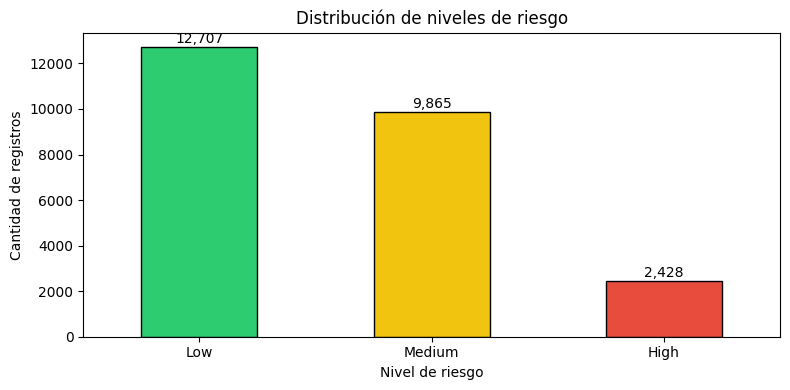

In [4]:
riesgos = df["failure_risk"].value_counts().reindex(["Low", "Medium", "High"], fill_value=0)
colores = ["#2ecc71", "#f1c40f", "#e74c3c"]

fig, ax = plt.subplots(figsize=(8, 4))
riesgos.plot(kind="bar", color=colores, edgecolor="black", ax=ax)
ax.set_title("Distribución de niveles de riesgo")
ax.set_xlabel("Nivel de riesgo")
ax.set_ylabel("Cantidad de registros")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(riesgos):
    ax.text(i, v + max(riesgos)*0.015, f"{v:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Preparación de los datos

- **`X`** son las **ocho métricas** utilizadas para predecir.
- **`y`** contiene la respuesta correcta (`failure_risk`).
- Excluimos `node_id`: es un identificador, no una métrica física. Lo reservamos para analizar posteriormente la generalización entre nodos.

**Importante:** las transformaciones que *aprenden parámetros* (como la estandarización) deben ajustarse solo con los datos de entrenamiento. Usaremos un `Pipeline` para K-NN.

In [ ]:
X = df.drop(columns=["node_id", "failure_risk"])
y = df["failure_risk"]

print("Variables de entrada:", X.columns.tolist())
print("Variable objetivo:", y.name)
print("Forma de X:", X.shape, "| Forma de y:", y.shape)

# Este ejercicio trabaja con ocho características numéricas sin nulos.
assert X.shape[1] == 8, "Se esperaban ocho características de entrada."
assert X.select_dtypes(include="number").shape[1] == X.shape[1], "Hay columnas no numéricas en X."
assert not X.isna().any().any(), "Existen nulos en X que deben tratarse."

Variables de entrada: ['cpu_usage_percent', 'ram_usage_percent', 'disk_usage_percent', 'network_usage_percent', 'active_jobs', 'idle_time_minutes', 'power_consumption_watts', 'temperature_celsius']
Variable objetivo: failure_risk
Forma de X: (25000, 8) | Forma de y: (25000,)


### 3.1 División 80/20: entrenamiento y prueba

- **80 % (20,000)**: los modelos conocen estas filas y sus etiquetas durante `.fit()`.
- **20 % (5,000)**: sirven para poner a prueba las predicciones mediante `.predict()`, **sin** entrenar con ellas.
- `stratify=y` mantiene proporciones similares de `Low`, `Medium`, `High`.
- `random_state=42` hace reproducible la partición.

Esta partición aleatoria evalúa **registros nuevos**, pero algunos pueden proceder de nodos presentes en ambos grupos. Una evaluación estricta sobre **nodos completamente desconocidos** requeriría separar por `node_id`.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
proporciones = pd.DataFrame({
    "Total (%)": y.value_counts(normalize=True).mul(100),
    "Entrenamiento (%)": y_train.value_counts(normalize=True).mul(100),
    "Prueba (%)": y_test.value_counts(normalize=True).mul(100)
}).reindex(["Low", "Medium", "High"])
display(proporciones.round(2))

Entrenamiento: (20000, 8) | Prueba: (5000, 8)


,Total (%),Entrenamiento (%),Prueba (%)
failure_risk,,,
Low,50.83,50.83,50.82
Medium,39.46,39.46,39.46
High,9.71,9.71,9.72


## 4. Definición de tres algoritmos

Aquí **solo creamos y configuramos** los modelos; aún **no están entrenados**.

| Modelo | Cómo decide | Parámetro principal |
|---|---|---|
| **K-NN** | Busca los registros más parecidos y vota entre sus 5 vecinos. | `n_neighbors=5` |
| **Árbol de decisión** | Aprende reglas y umbrales para separar las clases. | `max_depth=8` limita complejidad. |
| **Random Forest** | Combina decisiones de 100 árboles diferentes. | `n_estimators=100` |

**¿Por qué `StandardScaler` en K-NN?** Como K-NN compara distancias, no queremos que una columna con números grandes domine solo por sus unidades. El `Pipeline` ajusta el escalado **con el 80 % de entrenamiento**, evitando fuga de información. Los árboles no necesitan esa transformación.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "K-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

## 5. Entrenamiento y evaluación real

Ahora sí entrenamos. Para cada modelo, el bucle realiza:

1. **`.fit(X_train, y_train)`**: aprende con los 20,000 registros de entrenamiento.
2. **`.predict(X_test)`**: clasifica 5,000 registros sin conocer sus etiquetas reales.
3. Compara predicciones con `y_test` y calcula las métricas.
4. Mide el tiempo de entrenamiento con `time.perf_counter()`.

**Métricas:** *accuracy* (porcentaje global de aciertos), *precision* (pureza de lo predicho), *recall* (qué proporción de cada clase real identificó) y *F1* (equilibrio entre precisión y recall). El promedio **macro** trata por igual las tres categorías. **Recall High** es especialmente importante para no pasar por alto riesgos altos.

In [ ]:
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

resultados = []
predicciones_modelos = {}
orden_clases = ["Low", "Medium", "High"]

for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)  # ¡Aquí ocurre el entrenamiento!
    segundos = time.perf_counter() - inicio

    predicciones = modelo.predict(X_test)  # Las 5,000 predicciones
    predicciones_modelos[nombre] = predicciones

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision macro": precision_score(y_test, predicciones, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, predicciones, average="macro", zero_division=0),
        "Macro-F1": f1_score(y_test, predicciones, average="macro", zero_division=0),
        "Recall High": recall_score(y_test, predicciones, labels=["High"], average=None, zero_division=0)[0],
        "Tiempo entrenamiento (s)": segundos
    })

    print("\n" + "=" * 60)
    print(f"MODELO: {nombre} | Tiempo de entrenamiento: {segundos:.4f} s")
    print(classification_report(y_test, predicciones, labels=orden_clases, zero_division=0))

tabla_resultados = pd.DataFrame(resultados)
print("\nCOMPARACIÓN DE MODELOS (valores reales de esta ejecución):")
display(tabla_resultados.sort_values("Macro-F1", ascending=False).round(4))


MODELO: K-NN | Tiempo de entrenamiento: 0.0376 s
              precision    recall  f1-score   support

         Low       0.98      0.98      0.98      2541
      Medium       0.96      0.96      0.96      1973
        High       0.96      0.95      0.96       486

    accuracy                           0.97      5000
   macro avg       0.97      0.96      0.97      5000
weighted avg       0.97      0.97      0.97      5000


MODELO: Árbol de decisión | Tiempo de entrenamiento: 0.0929 s
              precision    recall  f1-score   support

         Low       0.98      0.97      0.97      2541
      Medium       0.94      0.96      0.95      1973
        High       0.94      0.90      0.92       486

    accuracy                           0.96      5000
   macro avg       0.95      0.94      0.95      5000
weighted avg       0.96      0.96      0.96      5000




MODELO: Random Forest | Tiempo de entrenamiento: 0.5380 s
              precision    recall  f1-score   support

         Low       0.98      0.98      0.98      2541
      Medium       0.97      0.97      0.97      1973
        High       0.96      0.95      0.96       486

    accuracy                           0.97      5000
   macro avg       0.97      0.97      0.97      5000
weighted avg       0.97      0.97      0.97      5000


COMPARACIÓN DE MODELOS (valores reales de esta ejecución):


,Modelo,Accuracy,Precision macro,Recall macro,Macro-F1,Recall High,Tiempo entrenamiento (s)
2,Random Forest,0.9744,0.9706,0.9670,0.9688,0.9486,0.5380
0,K-NN,0.9690,0.9666,0.9634,0.9650,0.9506,0.0376
1,Árbol de decisión,0.9588,0.9533,0.9416,0.9472,0.8951,0.0929


### 5.1 Matrices de confusión

En cada matriz, las **filas** corresponden al riesgo real y las **columnas** a la predicción. La **diagonal** cuenta aciertos; los valores fuera de la diagonal indican confusiones. En particular, revisa la fila `High` para saber cuántos casos de riesgo alto se confundieron con `Medium` o `Low`.

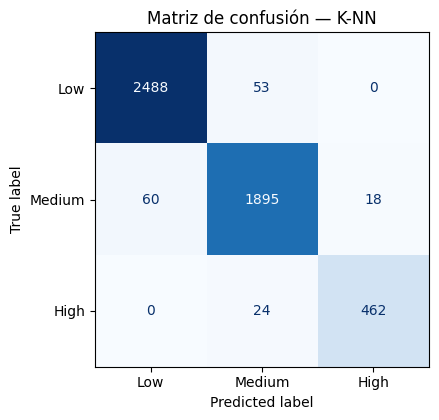

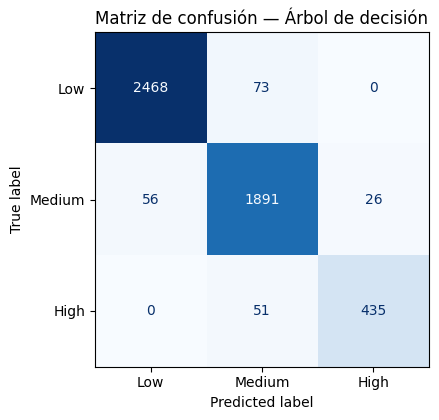

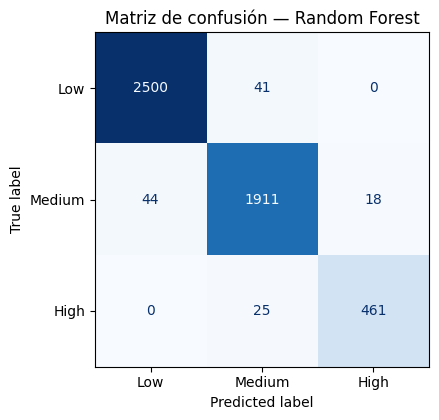

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

for nombre, predicciones in predicciones_modelos.items():
    fig, ax = plt.subplots(figsize=(5.3, 4.3))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=orden_clases,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"Matriz de confusión — {nombre}")
    plt.tight_layout()
    plt.show()

### 5.2 Comparación visual

No basta con mirar *accuracy*: utilizaremos **Macro-F1** y **Recall High** para analizar el equilibrio general y la detección de la clase más delicada.

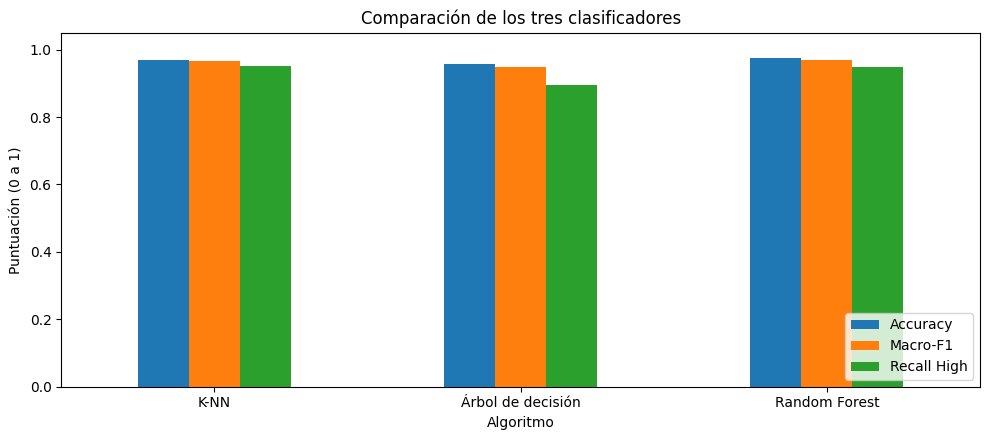

In [ ]:
comparacion_visual = tabla_resultados.set_index("Modelo")[["Accuracy", "Macro-F1", "Recall High"]]
ax = comparacion_visual.plot(kind="bar", figsize=(10, 4.5), ylim=(0, 1.05), rot=0)
ax.set_title("Comparación de los tres clasificadores")
ax.set_ylabel("Puntuación (0 a 1)")
ax.set_xlabel("Algoritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Selección del modelo para la demostración

Elegiremos automáticamente el modelo con mayor **Macro-F1** en esta comparación (y `Recall High` como segundo criterio en caso de empate). Así queda **definida `modelo_ganador`**, que faltaba cuando apareció el error `NameError`.

**Nota metodológica:** comparar varios modelos con el conjunto de prueba y elegir uno a partir de él puede introducir optimismo en la puntuación del ganador. Para un sistema real se recomienda seleccionar hiperparámetros/modelo con **validación cruzada dentro del entrenamiento** y utilizar un conjunto de prueba independiente una sola vez. En esta actividad seguimos el protocolo sencillo de comparación solicitado.

In [ ]:
tabla_ordenada = tabla_resultados.sort_values(
    ["Macro-F1", "Recall High"], ascending=[False, False]
).reset_index(drop=True)

nombre_ganador = tabla_ordenada.loc[0, "Modelo"]
modelo_ganador = modelos[nombre_ganador]  

print("Modelo elegido para la demostración:", nombre_ganador)
print("Macro-F1:", f"{tabla_ordenada.loc[0, 'Macro-F1']:.4f}")
print("Recall de High:", f"{tabla_ordenada.loc[0, 'Recall High']:.4f}")

Modelo elegido para la demostración: Random Forest
Macro-F1: 0.9688
Recall de High: 0.9486


## 7. Demostración funcional: registro de prueba

Primero comprobaremos cómo se comporta **cada modelo** frente a uno de los 5,000 registros de prueba. Aquí sí conocemos el riesgo real, por lo que podemos comparar las respuestas.

In [ ]:
fila = 0
registro_prueba = X_test.iloc[[fila]]
riesgo_real = y_test.iloc[fila]

print("Métricas del registro seleccionado:")
display(registro_prueba)
print("Riesgo real:", riesgo_real)

pruebas_individuales = []
for nombre, modelo in modelos.items():
    riesgo_estimado = modelo.predict(registro_prueba)[0]
    pruebas_individuales.append({
        "Modelo": nombre,
        "Predicción": riesgo_estimado,
        "Riesgo real": riesgo_real,
        "¿Acertó?": riesgo_estimado == riesgo_real
    })
display(pd.DataFrame(pruebas_individuales))

Métricas del registro seleccionado:


,cpu_usage_percent,ram_usage_percent,disk_usage_percent,network_usage_percent,active_jobs,idle_time_minutes,power_consumption_watts,temperature_celsius
9173,55.1,50.5,62.9,68.2,7,308,315,58.9


Riesgo real: Medium


,Modelo,Predicción,Riesgo real,¿Acertó?
0,K-NN,Medium,Medium,True
1,Árbol de decisión,Low,Medium,False
2,Random Forest,Low,Medium,False


### 7.1 Simulador: ingresar un equipo nuevo

**Esta es la celda que puedes mostrar en clase.** Cambia cualquiera de las ocho métricas dentro de `nuevo_equipo` y vuelve a ejecutar para obtener una nueva predicción.

Los valores deben corresponder a las **unidades y rangos esperados del dataset**. El resultado es una clasificación aprendida del conjunto de datos, **no** una garantía de que un equipo real sufrirá o no una avería.

In [ ]:
nuevo_equipo = {
    "cpu_usage_percent": 85.0,
    "ram_usage_percent": 78.0,
    "disk_usage_percent": 92.0,
    "network_usage_percent": 58.0,
    "active_jobs": 8,
    "idle_time_minutes": 35,
    "power_consumption_watts": 420,
    "temperature_celsius": 82.0
}

# Mantener el mismo orden y nombres de columnas del entrenamiento.
entrada = pd.DataFrame([nuevo_equipo])[X.columns]
if entrada.isna().any().any():
    raise ValueError("Faltan valores en la entrada.")

prediccion = modelo_ganador.predict(entrada)[0]
print("Modelo usado:", nombre_ganador)
print("Riesgo estimado:", prediccion)
print("\nResultados de los tres algoritmos:")
for nombre, modelo in modelos.items():
    print(f"- {nombre}: {modelo.predict(entrada)[0]}")

# Estos valores son puntuaciones probabilísticas del clasificador,
# pero NO deben interpretarse como probabilidades perfectamente calibradas.
if hasattr(modelo_ganador, "predict_proba"):
    proba = modelo_ganador.predict_proba(entrada)[0]
    clases = modelo_ganador.classes_
    print("\nProbabilidades estimadas por el modelo (no calibradas):")
    display(pd.DataFrame({"Categoría": clases, "Puntuación": proba}).round(4))

Modelo usado: Random Forest
Riesgo estimado: Medium

Resultados de los tres algoritmos:
- K-NN: High
- Árbol de decisión: Medium
- Random Forest: Medium

Probabilidades estimadas por el modelo (no calibradas):


,Categoría,Puntuación
0,High,0.48
1,Low,0.00
2,Medium,0.52


## 8. Guardar los resultados y el modelo entrenado

Esta celda crea una carpeta `resultados/` al lado del notebook y guarda:

- `comparacion_modelos.csv`: métricas medidas en la ejecución.
- `modelo_evaluado_80pct.joblib`: el modelo entrenado **solo con 20,000 registros** para esta evaluación y demostración.

**Seguridad:** los archivos `.joblib`/`pickle` solo deben abrirse si provienen de una fuente confiable. No es necesario cargar el archivo guardado para ejecutar la demostración del paso 7.

In [ ]:
from joblib import dump

carpeta_resultados = Path("resultados")
carpeta_resultados.mkdir(exist_ok=True)

tabla_resultados.to_csv(carpeta_resultados / "comparacion_modelos.csv", index=False)
dump(modelo_ganador, carpeta_resultados / "modelo_evaluado_80pct.joblib")
print("Resultados guardados en:", carpeta_resultados.resolve())

Resultados guardados en: /mnt/data/resultados


## 9. Conclusiones y límites del prototipo

Ejecuta la siguiente celda para recuperar **los nombres y resultados reales** de tus modelos. Completa tu conclusión escrita con lo que observaste en las matrices de confusión y los errores de `High`.

In [ ]:
mejor_global = tabla_ordenada.loc[0]
mejor_high = tabla_resultados.sort_values("Recall High", ascending=False).iloc[0]
mas_rapido = tabla_resultados.sort_values("Tiempo entrenamiento (s)").iloc[0]

print(f"Mejor Macro-F1: {mejor_global['Modelo']} ({mejor_global['Macro-F1']:.4f})")
print(f"Mayor recall de High: {mejor_high['Modelo']} ({mejor_high['Recall High']:.4f})")
print(f"Menor tiempo de entrenamiento: {mas_rapido['Modelo']} ({mas_rapido['Tiempo entrenamiento (s)']:.4f} s)")
print("\nNota: estos resultados pertenecen a los modelos evaluados con la partición 80/20.")

Mejor Macro-F1: Random Forest (0.9688)
Mayor recall de High: K-NN (0.9506)
Menor tiempo de entrenamiento: K-NN (0.0376 s)

Nota: estos resultados pertenecen a los modelos evaluados con la partición 80/20.
